<a href="https://colab.research.google.com/github/Nishan-vxm/customer-churn-prediction-xgboost/blob/main/Customer_church_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
df=pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
df.head()

In [ ]:
df.dtypes

In [ ]:
df.isnull().sum()

In [ ]:
df['gender'].unique()

In [ ]:
df['gender']=df['gender'].map({'Female':1,'Male':2})

In [ ]:
df.head()

In [ ]:
df['Partner'].unique()

In [ ]:
df['Partner']=df['Partner'].map({'Yes':1,'No':2})

In [ ]:
df.head()

In [ ]:
df['Dependents'].unique()

In [ ]:
df['Dependents']=df['Dependents'].map({'No':1,'Yes':2})

In [ ]:
df.head()

In [ ]:
df['PhoneService'].unique()

In [ ]:
df['PhoneService']=df['PhoneService'].map({'No':1,'Yes':2})
df.head()

In [ ]:
df['MultipleLines'].unique()
df['InternetService'].unique()
df['OnlineSecurity'].unique()






df['PaperlessBilling'].unique()

df['TotalCharges'].unique()

In [ ]:
df.dtypes

In [ ]:
df['MultipleLines']=df['MultipleLines'].map({'No phone service':0,'No':1,'Yes':2})

In [ ]:
df.dtypes

In [ ]:
df['InternetService'].unique()

In [ ]:
df['InternetService']=df['InternetService'].map({'DSL':0,'Fiber optic':1,'No':2})

In [ ]:
df['OnlineSecurity'].unique()

In [ ]:
df['OnlineSecurity']=df['OnlineSecurity'].map({'No':0,'Yes':1,'No internet service':2})

In [ ]:
df['OnlineBackup'].unique()

In [ ]:
df['OnlineBackup']=df['OnlineBackup'].map({'No':0,'Yes':1,'No internet service':2})

In [ ]:
df['DeviceProtection'].unique()

In [ ]:
df.head()

In [ ]:
df.dtypes

In [ ]:
df['OnlineBackup']=df['OnlineBackup'].map({'No':0,'Yes':1,'No internet service':2})

In [ ]:
df['TechSupport'].unique()

In [ ]:
df['TechSupport']=df['TechSupport'].map({'No':0,'Yes':1,'No internet service':2})

In [ ]:
df['StreamingTV'].unique()

In [ ]:
df['StreamingTV']=df['StreamingTV'].map({'No':0,'Yes':1,'No internet service':2})

In [ ]:
df.head()

In [ ]:
df['StreamingMovies'].unique()

In [ ]:
df['StreamingMovies']=df['StreamingMovies'].map({'No':0,'Yes':1,'No internet service':2})

In [ ]:
df['Contract'].unique()

In [ ]:
df['Contract']=df['Contract'].map({'Month-to-month':1,'One year':2,'Two year':3})

In [ ]:
df['PaperlessBilling'].unique()

In [ ]:
df['PaperlessBilling']=df['PaperlessBilling'].map({'Yes':1,'No':2})

In [ ]:
df['PaymentMethod'].unique()

array(['Electronic check', 'Mailed check', 'Bank transfer (automatic)',
       'Credit card (automatic)'], dtype=object)

In [ ]:
df['PaymentMethod']=df['PaymentMethod'].map({'Electronic check':0,'Mailed check':1,'Bank transfer (automatic)':2,'Credit card (automatic)':3})

In [ ]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,1,0,1,1,1,1,0,0,0,...,No,0,0,0,1,1,0,29.85,29.85,No
1,5575-GNVDE,2,0,2,1,34,2,1,0,1,...,Yes,0,0,0,2,2,1,56.95,1889.5,No
2,3668-QPYBK,2,0,2,1,2,2,1,0,1,...,No,0,0,0,1,1,1,53.85,108.15,Yes
3,7795-CFOCW,2,0,2,1,45,1,0,0,1,...,Yes,1,0,0,2,2,2,42.30,1840.75,No
4,9237-HQITU,1,0,2,1,2,2,1,1,0,...,No,0,0,0,1,1,0,70.70,151.65,Yes


In [ ]:
df.dtypes

,0
customerID,object
gender,int64
SeniorCitizen,int64
Partner,int64
Dependents,int64
tenure,int64
PhoneService,int64
MultipleLines,int64
InternetService,int64
OnlineSecurity,int64


In [ ]:
df['TotalCharges'].unique()

array(['29.85', '1889.5', '108.15', ..., '346.45', '306.6', '6844.5'],
      dtype=object)

In [ ]:
df['customerID']=df['customerID'].apply(lambda x:x.lower())

In [ ]:
import string
def remove_punc(txt):
    return txt.translate(str.maketrans('', '', string.punctuation))
df['customerID']=df['customerID'].apply(remove_punc)

In [ ]:
def remove_num(txt):
    new=""
    for i in txt:
        if not i.isdigit():
           new=new+i
    return new
df['customerID']=df['customerID'].apply(remove_num)

In [ ]:
def remove_emojis_special_ch(txt):
    new=""
    for i in txt:
        if i.isascii():
           new+=i
    return new
df['customerID']=df['customerID'].apply(remove_emojis_special_ch)

In [ ]:
import nltk

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

stop_words = set(stopwords.words('english'))

def remove_stopword(txt):
    words = word_tokenize(str(txt))
    clean = []

    for i in words:
        if i.lower() not in stop_words:
            clean.append(i)

    return ' '.join(clean)

df['customerID'] = df['customerID'].apply(remove_stopword)

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [ ]:
document=df['customerID']
vec=TfidfVectorizer()
X_1=vec.fit_transform(document)

In [ ]:
df['DeviceProtection'].unique()

array(['No', 'Yes', 'No internet service'], dtype=object)

In [ ]:
df['DeviceProtection']=df['DeviceProtection'].map({'No':1,'Yes':2,'No internet service':3})

In [ ]:
print(df['TotalCharges'].apply(type).value_counts())

print(df['TotalCharges'].isnull().sum())

print(df['TotalCharges'].tail(10).tolist())

TotalCharges
<class 'str'>    7043
Name: count, dtype: int64
0
['2625.25', '6886.25', '1495.1', '743.3', '1419.4', '1990.5', '7362.9', '346.45', '306.6', '6844.5']


In [ ]:
df['Churn'].unique()

array(['No', 'Yes'], dtype=object)

In [ ]:
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'].str.strip().replace('', pd.NA),
    errors='coerce'
)

print(df['TotalCharges'].dtype)
print(df['TotalCharges'].isnull().sum())

float64
11


In [ ]:
df.dtypes

,0
customerID,object
gender,int64
SeniorCitizen,int64
Partner,int64
Dependents,int64
tenure,int64
PhoneService,int64
MultipleLines,int64
InternetService,int64
OnlineSecurity,int64


Fitting 5 folds for each of 15 candidates, totalling 75 fits
Best Parameters:
{'subsample': 1.0, 'n_estimators': 200, 'min_child_weight': 1, 'max_depth': 5, 'learning_rate': 0.01, 'colsample_bytree': 0.8}

Best Cross-Validation ROC-AUC:
0.8478

Accuracy: 0.7544
Precision: 0.525
Recall: 0.7861
F1 Score: 0.6296
ROC-AUC: 0.8435

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.91      0.74      0.82      1035
       Churn       0.53      0.79      0.63       374

    accuracy                           0.75      1409
   macro avg       0.72      0.76      0.72      1409
weighted avg       0.80      0.75      0.77      1409



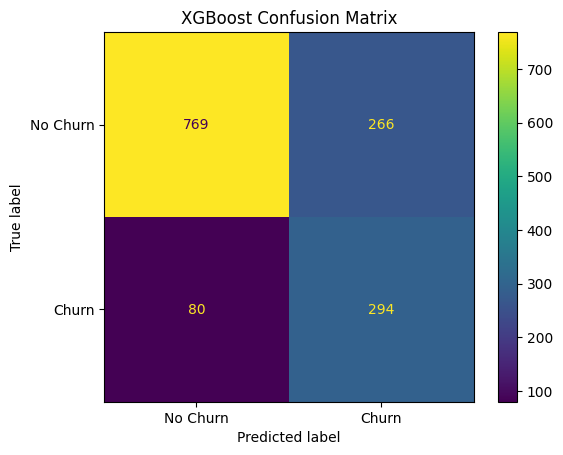


Top 15 Important Features:
Contract            0.425520
OnlineSecurity      0.204140
TechSupport         0.063631
InternetService     0.056057
tenure              0.039129
MonthlyCharges      0.027047
PaymentMethod       0.023576
TotalCharges        0.022652
StreamingMovies     0.020032
StreamingTV         0.019523
PaperlessBilling    0.019218
DeviceProtection    0.018136
MultipleLines       0.013154
PhoneService        0.012870
gender              0.010932
dtype: float32


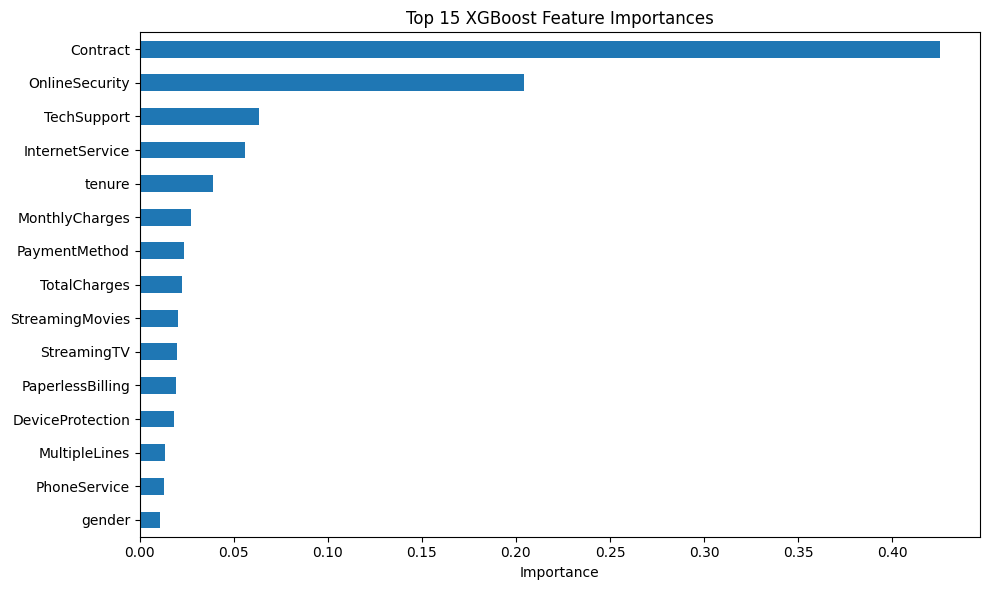

In [ ]:


from xgboost import XGBClassifier

from sklearn.model_selection import (
    train_test_split,
    RandomizedSearchCV,
    StratifiedKFold
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay,
    confusion_matrix
)

# 1. Copy dataset
data = df.copy()

# 2. Remove customerID if present
if 'customerID' in data.columns:
    data.drop(columns=['customerID'], inplace=True)

# 3. Convert target into 0 and 1
data['Churn'] = data['Churn'].map({
    'No': 0,
    'Yes': 1
}) if data['Churn'].dtype == 'object' else data['Churn']

# 4. Separate features and target
X = data.drop(columns=['Churn'])
y = data['Churn']

# 5. Remove any remaining missing values
# For this example, fill numeric columns with their median
X = X.replace([np.inf, -np.inf], np.nan)

numeric_cols = X.select_dtypes(include=np.number).columns
categorical_cols = X.select_dtypes(exclude=np.number).columns

X[numeric_cols] = X[numeric_cols].fillna(
    X[numeric_cols].median()
)

for col in categorical_cols:
    X[col] = X[col].fillna(
        X[col].mode().iloc[0]
    )

# Encode any remaining categorical columns
X = pd.get_dummies(X, drop_first=False, dtype=int)

# 6. Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 7. Calculate class imbalance weight
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_weight = negative_count / positive_count

# 8. Define XGBoost model
xgb = XGBClassifier(
    objective='binary:logistic',
    eval_metric='logloss',
    scale_pos_weight=scale_weight,
    random_state=42,
    n_jobs=-1
)

# 9. Hyperparameter search
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 4, 5, 6],
    'learning_rate': [0.01, 0.05, 0.1],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0],
    'min_child_weight': [1, 3, 5]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

search = RandomizedSearchCV(
    estimator=xgb,
    param_distributions=param_grid,
    n_iter=15,
    scoring='roc_auc',
    cv=cv,
    verbose=1,
    random_state=42,
    n_jobs=-1
)

# 10. Train
search.fit(X_train, y_train)

best_model = search.best_estimator_

print("Best Parameters:")
print(search.best_params_)

print("\nBest Cross-Validation ROC-AUC:")
print(round(search.best_score_, 4))

# 11. Predictions
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

# 12. Evaluation
print("\nAccuracy:", round(
    accuracy_score(y_test, y_pred), 4
))

print("Precision:", round(
    precision_score(y_test, y_pred, zero_division=0), 4
))

print("Recall:", round(
    recall_score(y_test, y_pred, zero_division=0), 4
))

print("F1 Score:", round(
    f1_score(y_test, y_pred, zero_division=0), 4
))

print("ROC-AUC:", round(
    roc_auc_score(y_test, y_prob), 4
))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=['No Churn', 'Churn'],
    zero_division=0
))

# 13. Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=['No Churn', 'Churn']
)

plt.title("XGBoost Confusion Matrix")
plt.show()

# 14. Feature importance
importance = pd.Series(
    best_model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("\nTop 15 Important Features:")
print(importance.head(15))

importance.head(15).sort_values().plot(
    kind='barh',
    figsize=(10, 6)
)

plt.title("Top 15 XGBoost Feature Importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")

print("Precision:", round(precision_score(y_test, y_pred, zero_division=0) * 100, 2), "%")

print("Recall:", round(recall_score(y_test, y_pred, zero_division=0) * 100, 2), "%")

print("F1 Score:", round(f1_score(y_test, y_pred, zero_division=0) * 100, 2), "%")

Accuracy: 75.44 %
Precision: 52.5 %
Recall: 78.61 %
F1 Score: 62.96 %
